<a href="https://colab.research.google.com/github/siojzz/UTSDEEPLEARNING/blob/task2-sekuens/kode/task2_rul/task2_sekuens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2 — Model Sekuens, Validasi per Mesin, Interval Prediksi, dan Keputusan Servis

**Ruang lingkup.** Bagian ini melanjutkan notebook eksplorasi dan menjawab butir (d) model sekuens, (e) validasi per mesin dengan RMSE dan skor asimetris per rentang RUL, serta (f) interval prediksi dan keputusan kapan mesin diservis.

**Ringkasan tahap sebelumnya.** Data latih berisi 900 mesin (umur 133–778 siklus) dan data uji 300 mesin yang berhenti pada siklus 50–455. Pengaturan operasi membentuk enam regime (silhouette 0,99), sehingga sensor dinormalisasi per regime. Delapan dari 21 sensor memiliki tren penuaan dan dipakai. Baseline *gradient boosting* mencapai RMSE 18,83 pada validasi per mesin, dengan prediksi cenderung terlalu optimistis pada RUL di bawah 100 siklus, sisi yang dihukum lebih berat oleh skor asimetris.

**Isi notebook.**
1. Dua arsitektur sekuens (GRU dan CNN 1D berdilasi) dibandingkan dengan baseline non-deep-learning pada pembagian mesin yang sama (5-fold *GroupKFold*).
2. **Kalibrasi bias terhadap skor asimetris.** Karena skor tumbuh eksponensial untuk prediksi yang terlalu besar, titik prediksi yang meminimalkan skor bukan rerata bersyarat, melainkan nilai yang sedikit lebih rendah. Pergeseran per rentang prediksi dicari dari residu validasi dan diuji dengan pemisahan mesin.
3. **Interval prediksi** dari kuantil residu validasi, dengan liputan diuji pada mesin yang tidak dipakai untuk kalibrasi.
4. **Simulasi kebijakan servis** berdasarkan prediksi titik dan batas bawah interval.
5. Prediksi uji final (`prediksi_rul.csv`) dari ansambel model fold.

**Alur.** 0 Persiapan → 1 Data dan jendela → 2 Baseline pembanding → 3 Model sekuens → 4 Pemilihan model → 5 Kalibrasi → 6 Interval → 7 Kebijakan servis → 8 Prediksi uji → 9 Kesimpulan → 10 Penyimpanan hasil.

## 0. Persiapan lingkungan dan data

Eksperimen memerlukan GPU (T4). Identitas akun GitHub pemilik pekerjaan ini diisi pada sel pertama.

In [2]:
AKUN_GITHUB = 'siojzz'
EMAIL_GITHUB = 'sfyrian21@gmail.com'

import torch, numpy, pandas, sklearn, sys, warnings
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan T4 GPU dulu: Runtime -> Change runtime type"

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [3]:
import os
if not os.path.exists('/content/data/rul_train.csv.gz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=23efbbaa-6caa-4cce-8680-16ce15e5e733
To: /content/data_uts_dl.zip
100% 396M/396M [00:04<00:00, 89.3MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [4]:
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull --no-edit upstream main
!git checkout -B task2-sekuens
!mkdir -p kode/task2_rul/hasil kode/task2_rul/bobot
!ls kode/task2_rul

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 135, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 135 (delta 4), reused 5 (delta 0), pack-reused 108 (from 1)
Receiving objects: 100% (135/135), 9.41 MiB | 14.11 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/UTSDEEPLEARNING
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 918 bytes | 918.00 KiB/s, done.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Updating 0532700..1498b1e
Fast-forward
 kode/task2_rul/hasil/task2_baseline.json |  176 ++
 kode/task2_rul/rul_data.py               |  161 ++
 kode/task2_rul/task2_eksplorasi.ipynb    | 2661 ++++++++++++++++++++++++++++++
 prediksi_rul.csv              

### Kode pendukung

`rul_data.py` (dari notebook eksplorasi) dipakai ulang dari repositori. Dua berkas baru ditulis di bawah ini.

| Berkas | Isi |
|---|---|
| `rul_eval.py` | evaluasi tanpa PyTorch: sampel mirip-uji, kalibrasi geser terhadap skor asimetris, interval dari kuantil residu, simulasi kebijakan servis |
| `rul_seq.py` | pra-pemrosesan yang sama dengan notebook eksplorasi, model GRU dan CNN 1D, pelatihan dan validasi silang per mesin |

In [5]:
%%writefile /content/UTSDEEPLEARNING/kode/task2_rul/rul_eval.py
import numpy as np, pandas as pd
from rul_data import CAP, metrik, skor_asimetris

BATAS_PRED = np.array([0, 20, 40, 60, 80, 100, 125, 1e9])      # bin berdasarkan nilai prediksi
NAMA_BIN = ['<20', '20-39', '40-59', '60-79', '80-99', '100-124', '>=125']

def layak_uji(df, min_siklus=50):
    """Baris yang mirip titik potong data uji: siklus >= min_siklus dan belum rusak (RUL >= 1)."""
    return ((df['siklus'] >= min_siklus) & (df['rul_mentah'] >= 1)).values

def mirip_uji(y, p, grup, layak, n_ulang=20):
    d = pd.DataFrame({'g': np.asarray(grup)[layak], 'i': np.where(layak)[0]})
    r = []
    for rep in range(n_ulang):
        idx = d.groupby('g').sample(1, random_state=rep)['i'].values
        r.append(metrik(y[idx], p[idx]))
    return {k: float(np.mean([x[k] for x in r])) for k in ('rmse', 'skor_total', 'skor_rata', 'bias')}

def _bin(p):
    return np.clip(np.digitize(p, BATAS_PRED) - 1, 0, len(BATAS_PRED) - 2)

# ---------- kalibrasi bias terhadap skor asimetris ----------
def cari_geser(y, p, grid=np.arange(0, 41, 1.0), min_n=200):
    """Untuk tiap bin prediksi, cari geser c (prediksi dikurangi c) yang meminimalkan skor asimetris rata-rata."""
    b = _bin(p)
    out = np.zeros(len(BATAS_PRED) - 1)
    for k in range(len(out)):
        m = b == k
        if m.sum() < min_n:
            continue
        sk = [skor_asimetris(np.clip(p[m] - c, 0, CAP) - y[m]).mean() for c in grid]
        out[k] = grid[int(np.argmin(sk))]
    return out

def terapkan_geser(p, geser):
    p = np.asarray(p, float)
    return np.clip(p - geser[_bin(p)], 0, CAP)

def _separuh(grup, seed=0):
    u = np.unique(grup)
    np.random.default_rng(seed).shuffle(u)
    return np.isin(grup, u[: len(u) // 2])

def skor_silang(y, p, grup, layak):
    """Mesin dibagi dua separuh; geser dicari pada satu separuh dan dinilai pada separuh lain (dua arah)."""
    A = _separuh(grup)
    sebelum, sesudah = [], []
    for fit_m, ev_m in ((A, ~A), (~A, A)):
        g = cari_geser(y[fit_m & layak], p[fit_m & layak])
        ev = ev_m & layak
        sebelum.append(metrik(y[ev], np.clip(p[ev], 0, CAP)))
        sesudah.append(metrik(y[ev], terapkan_geser(p[ev], g)))
    rata = lambda L, k: float(np.mean([x[k] for x in L]))
    return dict(rmse_sebelum=rata(sebelum, 'rmse'), rmse_sesudah=rata(sesudah, 'rmse'),
                skor_sebelum=rata(sebelum, 'skor_rata'), skor_sesudah=rata(sesudah, 'skor_rata'),
                bias_sebelum=rata(sebelum, 'bias'), bias_sesudah=rata(sesudah, 'bias'))

# ---------- interval prediksi dari residu ----------
def tabel_kuantil(y, p, q=(0.1, 0.9), min_n=100):
    b = _bin(p)
    t = np.full((len(BATAS_PRED) - 1, len(q)), np.nan)
    for k in range(t.shape[0]):
        m = b == k
        if m.sum() >= min_n:
            t[k] = np.quantile(y[m] - p[m], q)
    for j in range(t.shape[1]):
        t[:, j] = pd.Series(t[:, j]).interpolate(limit_direction='both').values
    return t

def interval(p, t):
    p = np.asarray(p, float); b = _bin(p)
    return np.clip(p + t[b, 0], 0, CAP), np.clip(p + t[b, 1], 0, CAP)

def liputan_silang(y, p, grup, layak, q=(0.1, 0.9)):
    """Kalibrasi interval pada separuh mesin, ukur liputan dan lebar pada separuh lain (dua arah)."""
    A = _separuh(grup)
    cov, lebar, per_bin = [], [], []
    for fit_m, ev_m in ((A, ~A), (~A, A)):
        t = tabel_kuantil(y[fit_m & layak], p[fit_m & layak], q)
        ev = ev_m & layak
        lo, hi = interval(p[ev], t)
        masuk = (y[ev] >= lo) & (y[ev] <= hi)
        cov.append(masuk.mean()); lebar.append((hi - lo).mean())
        b = _bin(p[ev])
        per_bin.append(pd.DataFrame({'b': b, 'masuk': masuk, 'lebar': hi - lo}).groupby('b').agg(liputan=('masuk', 'mean'), lebar=('lebar', 'mean'), n=('masuk', 'size')))
    pb = sum(x.reindex(range(len(NAMA_BIN))).fillna(0) * w for x, w in zip(per_bin, (0.5, 0.5)))
    pb.index = NAMA_BIN
    return dict(liputan=float(np.mean(cov)), lebar=float(np.mean(lebar))), pb

# ---------- simulasi kebijakan servis ----------
def simulasi_servis(df, p, H, min_siklus=50):
    """Servis pada siklus pertama (>= min_siklus) ketika nilai prediksi p <= H.
    Hasil: sisa umur sebenarnya pada saat servis, per mesin."""
    d = pd.DataFrame({'g': df['id_unit'].values, 's': df['siklus'].values, 'r': df['rul_mentah'].values, 'p': np.asarray(p, float)})
    d = d[d['s'] >= min_siklus]
    sisa = []
    for g, x in d.groupby('g'):
        a = x[x['p'] <= H]
        sisa.append(float(a['r'].iloc[0]) if len(a) else np.nan)
    r = np.array(sisa)
    ada = ~np.isnan(r)
    return dict(H=float(H), tidak_terdeteksi=float(100 * (~ada).mean()),
                terlambat_persen=float(100 * ((r <= 5) | ~ada).mean()),
                sisa_median=float(np.nanmedian(r)) if ada.any() else np.nan,
                sisa_p90=float(np.nanpercentile(r, 90)) if ada.any() else np.nan,
                terbuang_rata=float(np.nanmean(r)) if ada.any() else np.nan)


Writing /content/UTSDEEPLEARNING/kode/task2_rul/rul_eval.py


In [6]:
%%writefile /content/UTSDEEPLEARNING/kode/task2_rul/rul_seq.py
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import GroupKFold
from rul_data import *

def siapkan(tr, te, k=6, thr=0.1):
    """Pipeline pra-pemrosesan yang sama dengan notebook eksplorasi: normalisasi per regime, despike kausal,
    pengisian kausal, seleksi sensor berdasarkan tren (tanpa label). Menambahkan one-hot regime dan umur."""
    nm = Normalisasi('regime', k).fit(tr, SENS)
    trn, ten = nm.transform(tr), nm.transform(te)
    trn, _, skala = despike(trn, SENS)
    ten, _, _ = despike(ten, SENS, scale=skala)
    trc, tec = isi_kausal(trn, SENS), isi_kausal(ten, SENS)
    tren = tren_per_sensor(trc, SENS)
    pakai = [c for c in SENS if abs(tren[c]) >= thr]
    for d in (trc, tec):
        for r in range(k):
            d[f'reg{r}'] = (d['regime'] == r).astype(np.float32)
        d['umur'] = d['siklus'] / 500.0
    kolom = pakai + [f'reg{r}' for r in range(k)] + ['umur']
    return trc, tec, pakai, kolom

class GRURegresi(nn.Module):
    def __init__(self, f, h=64, p=0.2):
        super().__init__()
        self.gru = nn.GRU(f, h, num_layers=2, batch_first=True, dropout=p)
        self.head = nn.Sequential(nn.Linear(h, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 1))
    def forward(self, x):
        o, _ = self.gru(x)
        return self.head(o[:, -1]).squeeze(1)

class CNNRegresi(nn.Module):
    """CNN 1D kausal-longgar dengan dilasi 1, 2, 4, 8 (bidang reseptif 31 siklus)."""
    def __init__(self, f, h=64, p=0.2):
        super().__init__()
        def blk(i, o, d):
            return nn.Sequential(nn.Conv1d(i, o, 3, padding=d, dilation=d), nn.BatchNorm1d(o), nn.ReLU())
        self.body = nn.Sequential(blk(f, h, 1), blk(h, h, 2), blk(h, h, 4), blk(h, h, 8))
        self.head = nn.Sequential(nn.Linear(2 * h, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 1))
    def forward(self, x):
        z = self.body(x.transpose(1, 2))
        return self.head(torch.cat([z[:, :, -1], z.mean(2)], dim=1)).squeeze(1)

@torch.no_grad()
def prediksi(model, X, device='cuda', bs=4096):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(torch.from_numpy(X[i:i + bs]).to(device)).float().cpu())
    return torch.cat(out).numpy() * CAP

def latih_fold(model, Xtr, ytr, Xva, yva, epochs=12, lr=2e-3, bs=1024, device='cuda', seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model.to(device)
    Xt = torch.from_numpy(Xtr).to(device)
    yt = torch.from_numpy((ytr / CAP).astype(np.float32)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(Xt) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), device=device); tot = 0.0
        for i in range(0, len(Xt), bs):
            idx = perm[i:i + bs]
            loss = F.mse_loss(model(Xt[idx]), yt[idx])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item() * len(idx)
        pv = np.clip(prediksi(model, Xva, device), 0, CAP)
        rm = float(np.sqrt(np.mean((pv - yva) ** 2)))
        hist.append((tot / len(Xt), rm))
        print(f"  ep {ep + 1}: loss {hist[-1][0]:.5f} | RMSE validasi {rm:.2f}")
    del Xt, yt
    torch.cuda.empty_cache()
    return model, hist

def cv_sekuens(fn, X, y, grup, Xte, nama, slug, dir_bobot, n_fold=5, epochs=12, device='cuda'):
    """Validasi silang per mesin. Mengembalikan prediksi out-of-fold (RUL), prediksi uji tiap fold, dan riwayat latih.
    Bobot tiap fold disimpan; kelima model dipakai sebagai ansambel pada data uji."""
    oof = np.zeros(len(y), dtype=np.float32); te_pred, hist = [], []
    for f, (a, b) in enumerate(GroupKFold(n_fold).split(X, y, grup)):
        print(f"{nama} | fold {f + 1}/{n_fold}")
        model, h = latih_fold(fn(), X[a], y[a], X[b], y[b], epochs=epochs, device=device, seed=f)
        oof[b] = prediksi(model, X[b], device)
        te_pred.append(prediksi(model, Xte, device))
        torch.save(model.state_dict(), f"{dir_bobot}/{slug}_fold{f}.pt")
        hist.append(h)
        del model
        torch.cuda.empty_cache()
    return oof, np.array(te_pred), hist


Writing /content/UTSDEEPLEARNING/kode/task2_rul/rul_seq.py


## 1. Data dan jendela geser

Pra-pemrosesan sama dengan notebook eksplorasi (normalisasi per regime dengan k = 6, penanganan lonjakan dan nilai hilang secara kausal, delapan sensor terpilih). Ke dalam masukan ditambahkan *one-hot* regime dan umur mesin (siklus/500).

**Panjang jendela W = 50 siklus.** Siklus terakhir terpendek pada data uji adalah 50, sehingga setiap mesin uji memiliki jendela penuh tanpa isian. Jendela yang berakhir di awal riwayat latih diisi dengan baris pertama mesin (masa lalu) dan ditandai kanal *mask*; tidak ada informasi masa depan yang dipakai.

**Baris yang mirip uji.** Data uji berhenti pada titik acak sebelum mesin rusak, dengan siklus terakhir paling sedikit 50. Karena itu metrik utama dihitung pada baris validasi dengan siklus ≥ 50 dan RUL ≥ 1, dan ukuran "mirip-uji" mengambil satu titik acak per mesin (20 kali pengulangan). Skor asimetris total pada ukuran ini sebanding dengan penilaian uji, yaitu jumlah atas mesin.

In [7]:
import sys, json, os
sys.path.append('/content/UTSDEEPLEARNING/kode/task2_rul')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Markdown, display
from rul_data import *
from rul_eval import *
from rul_seq import *

REPO = '/content/UTSDEEPLEARNING'
OUT = f'{REPO}/kode/task2_rul/hasil'
BOBOT = f'{REPO}/kode/task2_rul/bobot'
W, EPOCHS, DEVICE = 50, 12, 'cuda'
HASIL, INFO, PER = {}, {}, {}

tr, te = load()
tr = add_rul(tr)
trc, tec, PAKAI, KOLOM = siapkan(tr, te, k=6, thr=0.1)
print("sensor dipakai:", PAKAI)

X, y, grup_id, siklus = buat_jendela(trc, KOLOM, W)
y = y.astype(np.float32)
layak = layak_uji(trc)
Xte_all, _, ute_all, _ = buat_jendela(tec, KOLOM, W)
last_idx = tec.groupby('id_unit', sort=False).tail(1).index.values
Xte, id_uji = Xte_all[last_idx], tec.loc[last_idx, 'id_unit'].values
assert (tec.loc[last_idx, 'siklus'].values == te.groupby('id_unit')['siklus'].max().loc[id_uji].values).all()

print(f"jendela latih {X.shape} | jendela uji (siklus terakhir) {Xte.shape} | baris mirip-uji: {layak.sum()} dari {len(layak)}")
INFO.update(W=W, epochs=EPOCHS, n_layak=int(layak.sum()), n_baris=int(len(layak)), n_uji=int(len(id_uji)), sensor=PAKAI)

sensor dipakai: ['s02', 's03', 's04', 's07', 's08', 's11', 's12', 's15']
jendela latih (254174, 50, 16) | jendela uji (siklus terakhir) (300, 50, 16) | baris mirip-uji: 209174 dari 254174


## 2. Baseline pembanding (non-deep-learning)

Baseline gradient boosting dari notebook eksplorasi dilatih ulang di sini dengan pembagian mesin yang sama persis dan diukur dengan protokol baru (baris mirip-uji), sehingga perbandingannya sepadan.

In [8]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor

def evaluasi(nama, p):
    p = np.clip(np.asarray(p, float), 0, CAP)
    a = metrik(y[layak], p[layak]); b = mirip_uji(y, p, grup_id, layak)
    HASIL[nama] = dict(rmse=a['rmse'], skor_rata=a['skor_rata'], bias=a['bias'], rmse_miripuji=b['rmse'],
                       skor_total_miripuji=b['skor_total'], skor_rata_miripuji=b['skor_rata'], bias_miripuji=b['bias'])
    PER[nama] = metrik_per_rentang(y[layak], p[layak])
    print(f"{nama}: RMSE {a['rmse']:.2f} | skor rata-rata {a['skor_rata']:.2f} | bias {a['bias']:+.2f} || mirip-uji: RMSE {b['rmse']:.2f}, skor total {b['skor_total']:.0f}")

N_HGB = 'Gradient boosting (baseline)'
Xf = fitur_jendela(trc, PAKAI, W=30)
oof_hgb = np.zeros(len(y))
for a, b in GroupKFold(5).split(Xf, y, grup_id):
    oof_hgb[b] = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0).fit(Xf.iloc[a], y[a]).predict(Xf.iloc[b])
evaluasi(N_HGB, oof_hgb)

Gradient boosting (baseline): RMSE 20.65 | skor rata-rata 22.92 | bias -0.30 || mirip-uji: RMSE 22.02, skor total 32429


## 3. Model sekuens: GRU dan CNN 1D berdilasi

Dua arsitektur dibandingkan, masing-masing dengan sekitar 60 ribu parameter:
- **GRU** dua lapis (64 unit tersembunyi) dengan lapisan keluaran dari keadaan pada langkah terakhir. GRU memproses jendela secara berurutan dan dapat menangkap urutan perubahan sensor.
- **CNN 1D berdilasi** (empat blok dengan dilasi 1, 2, 4, 8; bidang reseptif 31 siklus) dengan gabungan nilai langkah terakhir dan rerata sepanjang jendela. CNN memproses jendela secara paralel dan lebih cepat dilatih.

**Pelatihan.** Target adalah RUL/150 dengan galat kuadrat rata-rata, AdamW, jadwal *one-cycle*, 12 epoch, dan *gradient clipping*. Validasi per mesin dengan 5-fold *GroupKFold*, sehingga setiap mesin latih mendapat prediksi *out-of-fold* dari model yang tidak pernah melihatnya. Kelima model fold tiap arsitektur disimpan dan dipakai sebagai ansambel pada data uji.

In [9]:
ARSI = {'GRU': (lambda: GRURegresi(X.shape[2]), 'gru'),
        'CNN 1D': (lambda: CNNRegresi(X.shape[2]), 'cnn1d')}
OOF, TEPRED, HIST = {}, {}, {}
for nama, (fn, slug) in ARSI.items():
    oof, tep, hist = cv_sekuens(fn, X, y, grup_id, Xte, nama, slug, BOBOT, n_fold=5, epochs=EPOCHS, device=DEVICE)
    OOF[nama], TEPRED[nama], HIST[nama] = np.clip(oof, 0, CAP), tep, hist
    evaluasi(nama, OOF[nama])

GRU | fold 1/5
  ep 1: loss 0.12984 | RMSE validasi 21.27
  ep 2: loss 0.02487 | RMSE validasi 19.85
  ep 3: loss 0.02018 | RMSE validasi 17.56
  ep 4: loss 0.01704 | RMSE validasi 16.71
  ep 5: loss 0.01594 | RMSE validasi 16.59
  ep 6: loss 0.01521 | RMSE validasi 16.83
  ep 7: loss 0.01474 | RMSE validasi 16.90
  ep 8: loss 0.01426 | RMSE validasi 16.87
  ep 9: loss 0.01389 | RMSE validasi 16.76
  ep 10: loss 0.01350 | RMSE validasi 16.86
  ep 11: loss 0.01332 | RMSE validasi 16.84
  ep 12: loss 0.01319 | RMSE validasi 16.86
GRU | fold 2/5
  ep 1: loss 0.26786 | RMSE validasi 21.37
  ep 2: loss 0.02706 | RMSE validasi 19.49
  ep 3: loss 0.02182 | RMSE validasi 18.23
  ep 4: loss 0.01958 | RMSE validasi 17.91
  ep 5: loss 0.01821 | RMSE validasi 19.10
  ep 6: loss 0.01730 | RMSE validasi 17.58
  ep 7: loss 0.01640 | RMSE validasi 17.39
  ep 8: loss 0.01561 | RMSE validasi 17.61
  ep 9: loss 0.01503 | RMSE validasi 17.46
  ep 10: loss 0.01445 | RMSE validasi 17.66
  ep 11: loss 0.0140

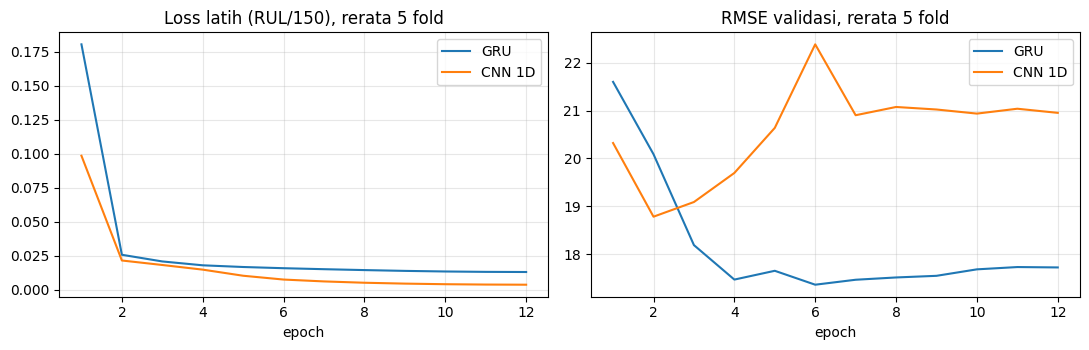

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for nama in ARSI:
    h = np.array(HIST[nama]).mean(0)                    # rerata antar fold: (epoch, [loss, RMSE])
    ax[0].plot(range(1, len(h) + 1), h[:, 0], label=nama)
    ax[1].plot(range(1, len(h) + 1), h[:, 1], label=nama)
ax[0].set_title('Loss latih (RUL/150), rerata 5 fold'); ax[1].set_title('RMSE validasi, rerata 5 fold')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

## 4. Perbandingan dan pemilihan model

Ketiga kandidat sekuens dibandingkan: GRU, CNN 1D, dan rata-rata keduanya (ansambel lintas arsitektur). Dipilih kandidat dengan **skor asimetris terkalibrasi silang** terendah, yaitu skor setelah bias dikalibrasi (bagian 5) dengan pergeseran yang dicari pada separuh mesin dan dinilai pada separuh lainnya. Kriteria ini dipilih karena penilaian uji memakai skor asimetris di samping RMSE.

In [11]:
KAND = {'GRU': (OOF['GRU'], TEPRED['GRU']),
        'CNN 1D': (OOF['CNN 1D'], TEPRED['CNN 1D']),
        'Rata-rata GRU+CNN': ((OOF['GRU'] + OOF['CNN 1D']) / 2, np.concatenate([TEPRED['GRU'], TEPRED['CNN 1D']]))}
evaluasi('Rata-rata GRU+CNN', KAND['Rata-rata GRU+CNN'][0])

SIL = {n: skor_silang(y, KAND[n][0], grup_id, layak) for n in KAND}
SIL[N_HGB] = skor_silang(y, oof_hgb, grup_id, layak)
tab = pd.DataFrame({n: {'RMSE (layak)': HASIL[n]['rmse'], 'skor rata-rata': HASIL[n]['skor_rata'], 'bias': HASIL[n]['bias'],
                        'RMSE mirip-uji': HASIL[n]['rmse_miripuji'], 'skor total mirip-uji': HASIL[n]['skor_total_miripuji'],
                        'skor rata-rata terkalibrasi (silang)': SIL[n]['skor_sesudah'], 'RMSE terkalibrasi (silang)': SIL[n]['rmse_sesudah']}
                    for n in [N_HGB] + list(KAND)}).T
display(tab.round(2))
TERBAIK = min(KAND, key=lambda n: SIL[n]['skor_sesudah'])
print("model terpilih:", TERBAIK)
INFO.update(terbaik=TERBAIK, silang={k: float(v) for k, v in SIL[TERBAIK].items()}, silang_hgb={k: float(v) for k, v in SIL[N_HGB].items()})

print("\nRincian per rentang RUL (baris mirip-uji). Bias positif = prediksi lebih besar dari aktual (terlalu optimistis).")
gab = pd.concat({n: PER[n][['n', 'rmse', 'bias', 'skor_rata']] for n in [N_HGB, 'GRU', 'CNN 1D']}, names=['model'])
display(gab.round(2))
for n in HASIL:
    HASIL[n]['per_rentang'] = {r: {k: float(v) for k, v in row.items()} for r, row in PER[n].iterrows()}

Rata-rata GRU+CNN: RMSE 20.04 | skor rata-rata 22.23 | bias -0.26 || mirip-uji: RMSE 21.47, skor total 32785


,RMSE (layak),skor rata-rata,bias,RMSE mirip-uji,skor total mirip-uji,skor rata-rata terkalibrasi (silang),RMSE terkalibrasi (silang)
Gradient boosting (baseline),20.65,22.92,-0.30,22.02,32429.06,10.90,24.45
GRU,19.39,21.31,-0.06,20.78,31564.63,9.77,23.40
CNN 1D,22.85,41.58,-0.47,24.20,56887.16,15.56,27.25
Rata-rata GRU+CNN,20.04,22.23,-0.26,21.47,32785.17,10.48,24.01


model terpilih: GRU

Rincian per rentang RUL (baris mirip-uji). Bias positif = prediksi lebih besar dari aktual (terlalu optimistis).


n   rmse   bias  skor_rata
model                        rentang                                         
Gradient boosting (baseline) 0-29              26100  12.11   6.07       3.21
                             30-59             27000  21.53   7.21      56.19
                             60-99             35940  31.02  13.88      71.00
                             100-149           42768  21.68   0.31       9.29
                             150 (batas atas)  77366  15.33 -11.99       3.15
GRU                          0-29              26100  11.22   5.40       5.14
                             30-59             27000  18.20   4.61      48.19
                             60-99             35940  29.24  12.57      66.15
                             100-149           42768  21.43   2.04       9.22
                             150 (batas atas)  77366  14.40 -10.55       3.24
CNN 1D                       0-29              26100  12.93   6.58       5.70
                             30-59             27000  24.41   8.95     140.46
                             60-99             35940  32.31  15.16     105.31
                             100-149           42768  23.39   0.01      12.49
                             150 (batas atas)  77366  18.98 -13.66       5.65

## 5. Kalibrasi bias terhadap skor asimetris

Skor asimetris memberi hukuman yang naik secara eksponensial untuk prediksi yang lebih besar dari RUL sebenarnya (d > 0, skala 10 siklus) dan lebih ringan untuk prediksi yang terlalu kecil (d < 0, skala 13 siklus). Akibatnya, sedikit prediksi yang sangat optimistis dapat mendominasi total skor. Titik prediksi yang meminimalkan skor bukan rerata bersyarat, melainkan nilai yang lebih rendah.

Untuk tiap rentang nilai prediksi dicari pergeseran c (prediksi dikurangi c, dibatasi 0 sampai 150) yang meminimalkan skor rata-rata pada data validasi. Karena pergeseran dipilih dari data yang sama dengan yang dinilai, efeknya diuji silang: pergeseran dicari pada separuh mesin dan dinilai pada separuh mesin lainnya. Angka silang di bawah inilah yang dipakai untuk menilai manfaatnya.

In [12]:
oof_b, te_b_all = KAND[TERBAIK]
geser = cari_geser(y[layak], oof_b[layak])
oof_cal = terapkan_geser(oof_b, geser)
evaluasi(f'{TERBAIK} + geser', oof_cal)

tab = pd.DataFrame({'rentang prediksi': NAMA_BIN, 'geser c (siklus)': geser}).set_index('rentang prediksi')
display(tab.T)
s = SIL[TERBAIK]
print(f"uji silang (pergeseran dicari pada separuh mesin, dinilai pada separuh lain): "
      f"skor rata-rata {s['skor_sebelum']:.2f} -> {s['skor_sesudah']:.2f} | RMSE {s['rmse_sebelum']:.2f} -> {s['rmse_sesudah']:.2f} | bias {s['bias_sebelum']:+.2f} -> {s['bias_sesudah']:+.2f}")
INFO['geser'] = [float(g) for g in geser]

GRU + geser: RMSE 23.22 | skor rata-rata 9.69 | bias -10.54 || mirip-uji: RMSE 22.50, skor total 10267


rentang prediksi,<20,20-39,40-59,60-79,80-99,100-124,>=125
geser c (siklus),1.0,1.0,0.0,0.0,1.0,11.0,18.0


uji silang (pergeseran dicari pada separuh mesin, dinilai pada separuh lain): skor rata-rata 21.31 -> 9.77 | RMSE 19.39 -> 23.40 | bias -0.06 -> -10.75


## 6. Interval prediksi

Interval 80% dibentuk dari kuantil residu validasi: untuk tiap rentang nilai prediksi (setelah kalibrasi), residu = aktual − prediksi, dan batas bawah serta atas adalah kuantil 10% dan 90% residu tersebut. Cara ini tidak mengandalkan asumsi sebaran galat dan menyesuaikan lebar interval dengan rentang prediksi, karena galat berbeda jauh antara RUL kecil dan RUL besar.

Liputan (proporsi nilai aktual yang masuk interval) diuji pada mesin yang tidak dipakai untuk menghitung kuantil. Pada data uji, prediksi titik berasal dari ansambel kelima model fold sehingga tidak lebih buruk daripada prediksi satu model yang dipakai pada kalibrasi; sebaran antar anggota ansambel dilaporkan sebagai ukuran ketidaksepakatan model.

interval 80% | liputan pada mesin yang tidak dipakai kalibrasi: 80.0% | lebar rata-rata: 43.4 siklus


,liputan,lebar rata-rata,jumlah baris
<20,0.801,20.797,8337.0
20-39,0.798,34.831,8926.0
40-59,0.800,39.325,8409.5
60-79,0.800,52.202,8558.0
80-99,0.799,76.471,10441.0
100-124,0.800,50.890,37309.5
>=125,0.800,25.784,22606.0


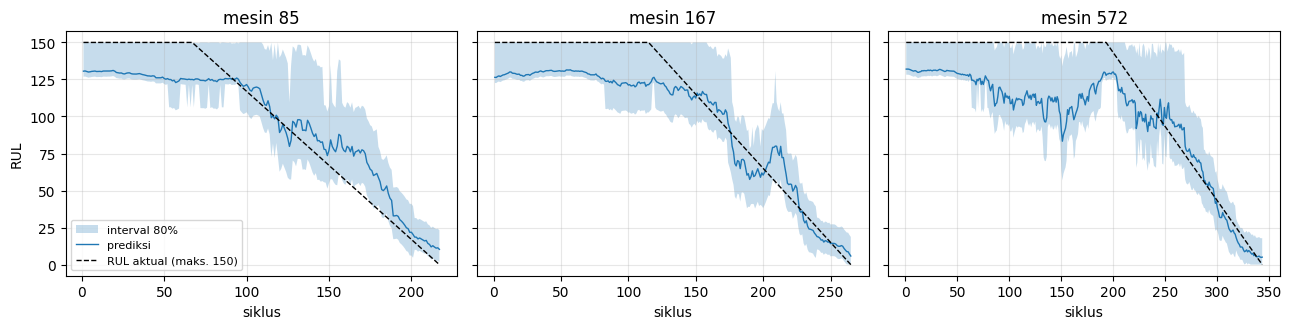

In [13]:
tq = tabel_kuantil(y[layak], oof_cal[layak])
res, pb = liputan_silang(y, oof_cal, grup_id, layak)
print(f"interval 80% | liputan pada mesin yang tidak dipakai kalibrasi: {100 * res['liputan']:.1f}% | lebar rata-rata: {res['lebar']:.1f} siklus")
display(pb.rename(columns={'liputan': 'liputan', 'lebar': 'lebar rata-rata', 'n': 'jumlah baris'}).round(3))
INFO['interval'] = dict(nominal=0.8, liputan=res['liputan'], lebar=res['lebar'],
                        per_bin={k: {c: float(v) for c, v in row.items()} for k, row in pb.iterrows()})

lo_oof, hi_oof = interval(oof_cal, tq)
umur_u = trc.groupby('id_unit')['siklus'].max()
contoh = [umur_u.index[(umur_u - umur_u.quantile(q)).abs().argmin()] for q in (0.2, 0.5, 0.8)]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, u in zip(ax, contoh):
    m = (trc['id_unit'] == u).values
    s_ = trc.loc[m, 'siklus'].values
    a.fill_between(s_, lo_oof[m], hi_oof[m], alpha=.25, label='interval 80%')
    a.plot(s_, oof_cal[m], lw=1, label='prediksi'); a.plot(s_, y[m], 'k--', lw=1, label='RUL aktual (maks. 150)')
    a.set_title(f'mesin {u}'); a.set_xlabel('siklus'); a.grid(alpha=.3)
ax[0].set_ylabel('RUL'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Kapan mesin sebaiknya diservis

Prediksi dan interval dipakai untuk membuat aturan servis sederhana: **servis pada siklus pertama (≥ 50) ketika sebuah nilai prediksi turun sampai batas H atau kurang.** Dua nilai yang dipantau dibandingkan: prediksi titik terkalibrasi, dan batas bawah interval 80% (lebih konservatif karena mempertimbangkan ketidakpastian).

Setiap aturan dinilai dari sisa umur **sebenarnya** pada saat servis dipicu:
- **terlambat:** sisa umur ≤ 5 siklus, atau alarm tidak pernah menyala sebelum mesin rusak;
- **sisa umur terbuang:** rata-rata sisa siklus yang belum dipakai ketika servis dilakukan. Servis terlalu dini membuang umur pakai, tetapi servis terlambat berarti kerusakan.

Simulasi memakai prediksi *out-of-fold* seluruh siklus tiap mesin latih, sehingga tidak ada mesin yang dinilai oleh model yang pernah melihatnya.

In [14]:
df_sim = trc[['id_unit', 'siklus', 'rul_mentah']]
baris = []
for H in (15, 25, 40, 60):
    for nama, pp in (('prediksi titik', oof_cal), ('batas bawah 10%', lo_oof)):
        r = simulasi_servis(df_sim, pp, H); r['dipantau'] = nama; baris.append(r)
servis = pd.DataFrame(baris).set_index(['dipantau', 'H'])
servis.columns = ['tidak terdeteksi (%)', 'terlambat (%)', 'sisa umur median', 'sisa umur persentil 90', 'sisa umur terbuang rata-rata']
display(servis.round(1))
INFO['servis'] = baris

,,tidak terdeteksi (%),terlambat (%),sisa umur median,sisa umur persentil 90,sisa umur terbuang rata-rata
dipantau,H,,,,,
prediksi titik,15.0,18.2,31.6,15.0,28.0,15.6
batas bawah 10%,15.0,0.4,1.3,31.0,48.5,31.4
prediksi titik,25.0,1.8,5.7,25.0,42.0,25.4
batas bawah 10%,25.0,0.0,0.4,42.0,61.0,42.7
prediksi titik,40.0,0.0,0.4,38.0,58.0,39.3
batas bawah 10%,40.0,0.0,0.0,59.0,86.1,61.7
prediksi titik,60.0,0.0,0.0,57.0,83.0,59.8
batas bawah 10%,60.0,0.0,0.0,82.5,123.0,88.0


## 8. Prediksi data uji

Prediksi titik pada tiap mesin uji adalah rata-rata dari model fold pada kandidat terpilih, ditambah kalibrasi geser, dan dibatasi pada 0–150. Berkas `prediksi_rul.csv` berisi kolom `id_unit` dan `rul`. Berkas tambahan `hasil/prediksi_rul_interval.csv` memuat interval 80% dan simpangan baku antar model fold untuk dipakai pada laporan.

In [15]:
te_b = te_b_all.mean(0)
p_fin = terapkan_geser(te_b, geser)
lo_te, hi_te = interval(p_fin, tq)
std_te = te_b_all.std(0)

sub = pd.DataFrame({'id_unit': id_uji, 'rul': np.round(p_fin, 2)})
assert len(sub) == te['id_unit'].nunique() and sub['id_unit'].is_unique and sub['rul'].between(0, CAP).all()
sub.to_csv(f'{REPO}/prediksi_rul.csv', index=False)
pd.DataFrame({'id_unit': id_uji, 'rul': np.round(p_fin, 2), 'batas_bawah_10': np.round(lo_te, 2),
              'batas_atas_90': np.round(hi_te, 2), 'std_antar_model': np.round(std_te, 2)}).to_csv(f'{OUT}/prediksi_rul_interval.csv', index=False)
print("tersimpan:", f'{REPO}/prediksi_rul.csv', "|", len(sub), "baris | model:", TERBAIK, f"({te_b_all.shape[0]} model fold)")
display(sub.head())
display(pd.DataFrame({'RUL prediksi': p_fin, 'lebar interval': hi_te - lo_te, 'std antar model': std_te}).describe().round(2).T)
INFO['uji'] = dict(rata_rul=float(p_fin.mean()), median_rul=float(np.median(p_fin)), lebar_interval_rata=float((hi_te - lo_te).mean()),
                   std_model_rata=float(std_te.mean()), skor_total_perkiraan=float(HASIL[f'{TERBAIK} + geser']['skor_rata_miripuji'] * len(sub)))

tersimpan: /content/UTSDEEPLEARNING/prediksi_rul.csv | 300 baris | model: GRU (5 model fold)


,id_unit,rul
0,1,59.08
1,2,31.40
2,6,95.46
3,8,127.24
4,16,26.30


,count,mean,std,min,25%,50%,75%,max
RUL prediksi,300.0,85.59,38.90,3.25,54.14,99.13,120.30,131.82
lebar interval,300.0,46.23,15.69,16.13,34.88,46.48,55.41,77.11
std antar model,300.0,3.77,2.92,0.30,1.67,2.90,5.24,17.55


## 9. Kesimpulan

Kesimpulan di bawah disusun otomatis dari hasil di atas, sehingga seluruh angka konsisten dengan tabel.

In [16]:
def _f(x, n=1): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t2b(H, info, per):
    t = []
    nm = [N_HGB, 'GRU', 'CNN 1D', 'Rata-rata GRU+CNN']
    baris = "; ".join(f"{n}: RMSE {_f(H[n]['rmse'], 2)}, skor rata-rata {_f(H[n]['skor_rata'])}" for n in nm)
    b = info['terbaik']; sh = info['silang_hgb']; sb = info['silang']
    t.append(f"**1. Perbandingan model.** Pada validasi per mesin (5-fold) dengan {info['n_layak']} baris yang menyerupai titik potong data uji, {baris}. "
             f"Setelah kalibrasi bias dan uji silang, skor asimetris rata-rata baseline adalah {_f(sh['skor_sesudah'])} dan kandidat terpilih **{b}** {_f(sb['skor_sesudah'])} "
             f"(RMSE terkalibrasi {_f(sh['rmse_sesudah'], 2)} dan {_f(sb['rmse_sesudah'], 2)}). "
             f"RMSE {b} lebih rendah {_f(100 * (1 - H[b]['rmse'] / H[N_HGB]['rmse']), 0)}% dibanding baseline sebelum kalibrasi.")
    pr = per[b]; terburuk = pr['rmse'].idxmax(); opt = [r for r in pr.index if pr.loc[r, 'bias'] > 0]
    t.append(f"**2. Per rentang RUL ({b}).** RMSE terbesar ada pada rentang {terburuk} ({_f(pr.loc[terburuk, 'rmse'], 2)}) dan terkecil pada {pr['rmse'].idxmin()} ({_f(pr['rmse'].min(), 2)}). "
             + (f"Bias positif (prediksi lebih besar dari aktual, sisi yang dihukum lebih berat) muncul pada rentang: {', '.join(opt)}." if opt else "Tidak ada rentang dengan bias positif."))
    g = info['geser']
    t.append(f"**3. Kalibrasi terhadap skor asimetris.** Pergeseran per rentang prediksi adalah {', '.join(f'{n}: {_f(v, 0)}' for n, v in zip(NAMA_BIN, g))} siklus. "
             f"Pada uji silang antar separuh mesin, skor asimetris rata-rata berubah dari {_f(sb['skor_sebelum'])} menjadi {_f(sb['skor_sesudah'])}, "
             f"RMSE dari {_f(sb['rmse_sebelum'], 2)} menjadi {_f(sb['rmse_sesudah'], 2)}, dan bias rata-rata dari {_f(sb['bias_sebelum'], 2)} menjadi {_f(sb['bias_sesudah'], 2)} siklus. "
             + (("Kalibrasi menurunkan skor" + (", dengan imbalan kenaikan RMSE, sesuai sifat skor yang menghukum optimisme lebih berat." if sb['rmse_sesudah'] > sb['rmse_sebelum'] else " tanpa menaikkan RMSE.")) if sb['skor_sesudah'] < sb['skor_sebelum'] else
                "Kalibrasi tidak menurunkan skor pada uji silang, sehingga manfaatnya tidak terbukti."))
    iv = info['interval']
    pbv = {k: v for k, v in iv['per_bin'].items() if v['n'] > 0}
    kb_min, kb_max = min(pbv, key=lambda k: pbv[k]['lebar']), max(pbv, key=lambda k: pbv[k]['lebar'])
    t.append(f"**4. Interval prediksi.** Interval 80% dari kuantil residu memiliki liputan {_f(100 * iv['liputan'])}% pada mesin yang tidak dipakai untuk kalibrasi (nominal 80%) dengan lebar rata-rata {_f(iv['lebar'])} siklus. "
             f"Lebar rata-rata paling kecil ada pada rentang prediksi {kb_min} ({_f(pbv[kb_min]['lebar'])} siklus) dan paling besar pada {kb_max} ({_f(pbv[kb_max]['lebar'])} siklus).")
    kandidat = []
    for dip in ('prediksi titik', 'batas bawah 10%'):
        ok = [r for r in info['servis'] if r['dipantau'] == dip and r['terlambat_persen'] <= 5]
        if ok:
            r = min(ok, key=lambda r: r['H']); kandidat.append(f"{dip} dengan H = {_f(r['H'], 0)} (terlambat {_f(r['terlambat_persen'])}%, sisa umur terbuang rata-rata {_f(r['terbuang_rata'])} siklus, median {_f(r['sisa_median'])})")
    t.append("**5. Kebijakan servis.** " + ("Batas H terkecil yang menjaga persentase servis terlambat tidak lebih dari 5%: " + "; ".join(kandidat) + ". "
             if kandidat else "Pada nilai H yang diuji, tidak ada aturan yang menjaga servis terlambat di bawah 5%. ")
             + "Memantau batas bawah interval membuat servis dipicu lebih awal daripada prediksi titik untuk H yang sama, sehingga mengurangi risiko terlambat dengan biaya sisa umur terbuang yang lebih besar; pilihan akhir bergantung pada biaya relatif kerusakan mendadak dibanding servis dini.")
    u = info['uji']
    t.append(f"**6. Prediksi uji.** Prediksi RUL untuk {info['n_uji']} mesin uji memiliki rerata {_f(u['rata_rul'])} dan median {_f(u['median_rul'])} siklus; lebar interval rata-rata {_f(u['lebar_interval_rata'])} dan simpangan baku antar model fold rata-rata {_f(u['std_model_rata'], 2)}. "
             f"Berdasarkan skor rata-rata mirip-uji, skor asimetris total pada {info['n_uji']} mesin diperkirakan sekitar {_f(u['skor_total_perkiraan'], 0)}, angka kasar karena sangat dipengaruhi segelintir prediksi optimistis.")
    t.append("**7. Keterbatasan.** Kalibrasi, kuantil interval, dan pemilihan kandidat memakai residu dari data validasi yang sama (dikurangi dengan uji silang antar separuh mesin). "
             "Interval dikalibrasi pada prediksi satu model per mesin, sedangkan prediksi uji berasal dari ansambel, sehingga interval uji cenderung konservatif. "
             "Hiperparameter model (jumlah unit, epoch, panjang jendela) belum disetel secara sistematis, dan fungsi kerugian pelatihan adalah galat kuadrat, bukan skor asimetris.")
    return "\n\n".join(t)

display(Markdown(buat_kesimpulan_t2b(HASIL, INFO, PER)))

**1. Perbandingan model.** Pada validasi per mesin (5-fold) dengan 209174 baris yang menyerupai titik potong data uji, Gradient boosting (baseline): RMSE 20,65, skor rata-rata 22,9; GRU: RMSE 19,39, skor rata-rata 21,3; CNN 1D: RMSE 22,85, skor rata-rata 41,6; Rata-rata GRU+CNN: RMSE 20,04, skor rata-rata 22,2. Setelah kalibrasi bias dan uji silang, skor asimetris rata-rata baseline adalah 10,9 dan kandidat terpilih **GRU** 9,8 (RMSE terkalibrasi 24,45 dan 23,40). RMSE GRU lebih rendah 6% dibanding baseline sebelum kalibrasi.

**2. Per rentang RUL (GRU).** RMSE terbesar ada pada rentang 60-99 (29,24) dan terkecil pada 0-29 (11,22). Bias positif (prediksi lebih besar dari aktual, sisi yang dihukum lebih berat) muncul pada rentang: 0-29, 30-59, 60-99, 100-149.

**3. Kalibrasi terhadap skor asimetris.** Pergeseran per rentang prediksi adalah <20: 1, 20-39: 1, 40-59: 0, 60-79: 0, 80-99: 1, 100-124: 11, >=125: 18 siklus. Pada uji silang antar separuh mesin, skor asimetris rata-rata berubah dari 21,3 menjadi 9,8, RMSE dari 19,39 menjadi 23,40, dan bias rata-rata dari -0,06 menjadi -10,75 siklus. Kalibrasi menurunkan skor, dengan imbalan kenaikan RMSE, sesuai sifat skor yang menghukum optimisme lebih berat.

**4. Interval prediksi.** Interval 80% dari kuantil residu memiliki liputan 80,0% pada mesin yang tidak dipakai untuk kalibrasi (nominal 80%) dengan lebar rata-rata 43,4 siklus. Lebar rata-rata paling kecil ada pada rentang prediksi <20 (20,8 siklus) dan paling besar pada 80-99 (76,5 siklus).

**5. Kebijakan servis.** Batas H terkecil yang menjaga persentase servis terlambat tidak lebih dari 5%: prediksi titik dengan H = 40 (terlambat 0,4%, sisa umur terbuang rata-rata 39,3 siklus, median 38,0); batas bawah 10% dengan H = 15 (terlambat 1,3%, sisa umur terbuang rata-rata 31,4 siklus, median 31,0). Memantau batas bawah interval membuat servis dipicu lebih awal daripada prediksi titik untuk H yang sama, sehingga mengurangi risiko terlambat dengan biaya sisa umur terbuang yang lebih besar; pilihan akhir bergantung pada biaya relatif kerusakan mendadak dibanding servis dini.

**6. Prediksi uji.** Prediksi RUL untuk 300 mesin uji memiliki rerata 85,6 dan median 99,1 siklus; lebar interval rata-rata 46,2 dan simpangan baku antar model fold rata-rata 3,77. Berdasarkan skor rata-rata mirip-uji, skor asimetris total pada 300 mesin diperkirakan sekitar 3422, angka kasar karena sangat dipengaruhi segelintir prediksi optimistis.

**7. Keterbatasan.** Kalibrasi, kuantil interval, dan pemilihan kandidat memakai residu dari data validasi yang sama (dikurangi dengan uji silang antar separuh mesin). Interval dikalibrasi pada prediksi satu model per mesin, sedangkan prediksi uji berasal dari ansambel, sehingga interval uji cenderung konservatif. Hiperparameter model (jumlah unit, epoch, panjang jendela) belum disetel secara sistematis, dan fungsi kerugian pelatihan adalah galat kuadrat, bukan skor asimetris.

## 10. Penyimpanan hasil

Hasil perbandingan model, kalibrasi, interval, dan simulasi servis disimpan dalam `hasil/task2_sekuens.json`. Kode, bobot model fold, dan prediksi uji di-commit ke branch `task2-sekuens`.

In [17]:
with open(f'{OUT}/task2_sekuens.json', 'w') as f:
    json.dump({'info': INFO, 'hasil': HASIL}, f, indent=2, default=float)
%cd /content/UTSDEEPLEARNING
!git add kode/task2_rul/rul_eval.py kode/task2_rul/rul_seq.py kode/task2_rul/hasil/task2_sekuens.json kode/task2_rul/hasil/prediksi_rul_interval.csv kode/task2_rul/bobot/*.pt prediksi_rul.csv
!git commit -m "Task 2: model sekuens GRU dan CNN 1D, kalibrasi skor asimetris, interval prediksi, kebijakan servis"
!git push origin task2-sekuens

/content/UTSDEEPLEARNING
[task2-sekuens dbaaff6] Task 2: model sekuens GRU dan CNN 1D, kalibrasi skor asimetris, interval prediksi, kebijakan servis
 15 files changed, 1159 insertions(+), 300 deletions(-)
 create mode 100644 kode/task2_rul/bobot/cnn1d_fold0.pt
 create mode 100644 kode/task2_rul/bobot/cnn1d_fold1.pt
 create mode 100644 kode/task2_rul/bobot/cnn1d_fold2.pt
 create mode 100644 kode/task2_rul/bobot/cnn1d_fold3.pt
 create mode 100644 kode/task2_rul/bobot/cnn1d_fold4.pt
 create mode 100644 kode/task2_rul/bobot/gru_fold0.pt
 create mode 100644 kode/task2_rul/bobot/gru_fold1.pt
 create mode 100644 kode/task2_rul/bobot/gru_fold2.pt
 create mode 100644 kode/task2_rul/bobot/gru_fold3.pt
 create mode 100644 kode/task2_rul/bobot/gru_fold4.pt
 create mode 100644 kode/task2_rul/hasil/prediksi_rul_interval.csv
 create mode 100644 kode/task2_rul/hasil/task2_sekuens.json
 create mode 100644 kode/task2_rul/rul_eval.py
 create mode 100644 kode/task2_rul/rul_seq.py
Enumerating objects: 26, 